
# Pooya Valizadeh

**GitHub:** [PooyaValizadeh](https://github.com/PooyaValizadeh)  
**Kaggle:** [PooyaValizadeh](https://www.kaggle.com/PooyaValizadeh)

---

In [148]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

In [149]:
model = keras.models.load_model("model_cifar10.keras")

In [150]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 3072)      │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 50)        │    153,650 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 50)        │        200 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 50)        │      2,550 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 3122)      │          0 │ flatten_1[0][0],  │
│ (Concatenate)       │                   │            │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 10)        │     31,230 │ concatenate_1[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 375,162 (1.43 MB)

 Trainable params: 187,530 (732.54 KB)

 Non-trainable params: 100 (400.00 B)

 Optimizer params: 187,532 (732.55 KB)

In [151]:
(xtrain , ytrain) , (xtest,ytest) = keras.datasets.cifar10.load_data()

In [152]:
X = np.concatenate([xtrain, xtest], axis=0)
y = np.concatenate([ytrain, ytest], axis=0)

In [153]:
from sklearn.model_selection import train_test_split as tts
xtrain1 , xtest1 , ytrain1 , ytest1= tts(X,y,test_size=0.15,random_state= 26 , stratify= y)
xtrain_1 , xval1, ytrain_1 , yval1 = tts( xtrain1 , ytrain1 , test_size=0.15 , random_state= 26 , stratify= ytrain1)

In [154]:
xtrain_1.shape , xval1.shape, ytrain_1.shape , yval1.shape , xtest1.shape , ytest1.shape

((43350, 32, 32, 3),
 (7650, 32, 32, 3),
 (43350, 1),
 (7650, 1),
 (9000, 32, 32, 3),
 (9000, 1))

In [155]:
max(xtrain_1.reshape(-1,1))

array([255], dtype=uint8)

In [156]:
xtrain_ = xtrain_1 / 255
xtest = xtest1 / 255
xval = xval1 / 255

In [157]:
ytrain_ = keras.utils.to_categorical(ytrain_1)
ytest = keras.utils.to_categorical(ytest1)
yval =keras.utils.to_categorical(yval1)

In [158]:
model.layers

[<InputLayer name=input_layer_1, built=True>,
 <Flatten name=flatten_1, built=True>,
 <Dense name=dense_3, built=True>,
 <BatchNormalization name=batch_normalization_1, built=True>,
 <Dense name=dense_4, built=True>,
 <Concatenate name=concatenate_1, built=True>,
 <Dense name=dense_5, built=True>]

In [159]:
model.layers[2].activation = keras.activations.selu
model.layers[4].activation = keras.activations.selu

model.layers[2].kernel_initializer = keras.initializers.LecunNormal()
model.layers[4].kernel_initializer = keras.initializers.LecunNormal()

In [160]:
model.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer="Adam",metrics=[keras.metrics.CategoricalAccuracy()])

In [161]:
history = model.fit(xtrain_,ytrain_,epochs=50,validation_data=(xval,yval),callbacks=[keras.callbacks.EarlyStopping(patience=10,restore_best_weights=True)])

Epoch 1/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - categorical_accuracy: 0.4729 - loss: 1.5588 - val_categorical_accuracy: 0.4892 - val_loss: 1.5212
Epoch 2/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - categorical_accuracy: 0.4915 - loss: 1.4854 - val_categorical_accuracy: 0.4620 - val_loss: 1.6072
Epoch 3/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - categorical_accuracy: 0.4920 - loss: 1.4732 - val_categorical_accuracy: 0.4848 - val_loss: 1.5420
Epoch 4/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - categorical_accuracy: 0.5006 - loss: 1.4487 - val_categorical_accuracy: 0.4693 - val_loss: 1.5555
Epoch 5/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - categorical_accuracy: 0.5012 - loss: 1.4446 - val_categorical_accuracy: 0.4703 - val_loss: 1.5593
Epoch 6/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - categorical_accuracy: 0.5079 - loss: 1.4271 - val_categorical_accuracy: 0.4346 - val_loss: 1.7105
Epoch 7/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - categorical_accurac

In [ ]:
pd.DataFrame(history.history).plot()

In [163]:
model.layers[2].activation = keras.activations.relu
model.layers[4].activation = keras.activations.relu

In [164]:
model.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer="Adam",metrics=[keras.metrics.CategoricalAccuracy()])

In [165]:
history1 = model.fit(xtrain_,ytrain_,epochs=50,validation_data=(xval,yval),callbacks=[keras.callbacks.EarlyStopping(patience=10,restore_best_weights=True)])

Epoch 1/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - categorical_accuracy: 0.4926 - loss: 1.4889 - val_categorical_accuracy: 0.4365 - val_loss: 1.6930
Epoch 2/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - categorical_accuracy: 0.4961 - loss: 1.4591 - val_categorical_accuracy: 0.4933 - val_loss: 1.4994
Epoch 3/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - categorical_accuracy: 0.5018 - loss: 1.4449 - val_categorical_accuracy: 0.4677 - val_loss: 1.5420
Epoch 4/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - categorical_accuracy: 0.4992 - loss: 1.4452 - val_categorical_accuracy: 0.4847 - val_loss: 1.4928
Epoch 5/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - categorical_accuracy: 0.5019 - loss: 1.4414 - val_categorical_accuracy: 0.4661 - val_loss: 1.5368
Epoch 6/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - categorical_accuracy: 0.5026 - loss: 1.4311 - val_categorical_accuracy: 0.4908 - val_loss: 1.4823
Epoch 7/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - categorical_accuracy

<Axes: >

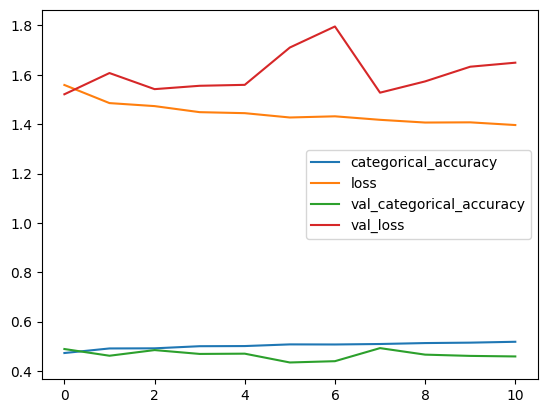

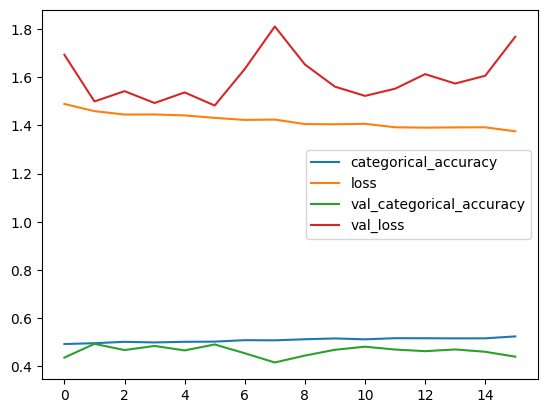

In [166]:
pd.DataFrame(history.history).plot()
pd.DataFrame(history1.history).plot()

In [167]:
ytrain_1 = (ytrain_1 == 7).astype(int)

In [168]:
ytest1 = (ytest1 == 7).astype(int)

In [169]:
yval1 = (yval1 == 7).astype(int)

In [170]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 3072)      │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 50)        │    153,650 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 50)        │        200 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 50)        │      2,550 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 3122)      │          0 │ flatten_1[0][0],  │
│ (Concatenate)       │                   │            │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 10)        │     31,230 │ concatenate_1[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 562,692 (2.15 MB)

 Trainable params: 187,530 (732.54 KB)

 Non-trainable params: 100 (400.00 B)

 Optimizer params: 375,062 (1.43 MB)

In [171]:
model.layers[0].trainable = False
model.layers[1].trainable = False
model.layers[2].trainable = False
model.layers[3].trainable = False
model.layers[4].trainable = False
model.layers[5].trainable = False

In [172]:
x = model.layers[-2].output

output = keras.layers.Dense(2, activation="sigmoid" , name = "kos")(x)

new_model = keras.Model(
    inputs=model.input,
    outputs=output
)


for layer in new_model.layers[:-1]:
    layer.trainable = False

In [173]:
ytrain_ = keras.utils.to_categorical(ytrain_1)
ytest = keras.utils.to_categorical(ytest1)
yval =keras.utils.to_categorical(yval1)

In [174]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 3072)      │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 50)        │    153,650 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 50)        │        200 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 50)        │      2,550 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 3122)      │          0 │ flatten_1[0][0],  │
│ (Concatenate)       │                   │            │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 10)        │     31,230 │ concatenate_1[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 562,692 (2.15 MB)

 Trainable params: 31,230 (121.99 KB)

 Non-trainable params: 156,400 (610.94 KB)

 Optimizer params: 375,062 (1.43 MB)

In [175]:
new_model.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer="Adam",metrics=[keras.metrics.CategoricalAccuracy()])

In [176]:
history2 = new_model.fit(xtrain_,ytrain_,epochs=50,validation_data=(xval,yval),callbacks=[keras.callbacks.EarlyStopping(patience=10,restore_best_weights=True)])

Epoch 1/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - categorical_accuracy: 0.9051 - loss: 0.2816 - val_categorical_accuracy: 0.9174 - val_loss: 0.2322
Epoch 2/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - categorical_accuracy: 0.9136 - loss: 0.2445 - val_categorical_accuracy: 0.9116 - val_loss: 0.2947
Epoch 3/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - categorical_accuracy: 0.9169 - loss: 0.2359 - val_categorical_accuracy: 0.9187 - val_loss: 0.2388
Epoch 4/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - categorical_accuracy: 0.9172 - loss: 0.2331 - val_categorical_accuracy: 0.9125 - val_loss: 0.3039
Epoch 5/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - categorical_accuracy: 0.9196 - loss: 0.2279 - val_categorical_accuracy: 0.9193 - val_loss: 0.2361
Epoch 6/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - categorical_accuracy: 0.9204 - loss: 0.2264 - val_categorical_accuracy: 0.9188 - val_loss: 0.2311
Epoch 7/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - categorical_accuracy

In [179]:
new_model.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer=keras.optimizers.RMSprop(),metrics=[keras.metrics.CategoricalAccuracy()])

In [180]:
history3 = new_model.fit(xtrain_,ytrain_,epochs=50,validation_data=(xval,yval),callbacks=[keras.callbacks.EarlyStopping(patience=10,restore_best_weights=True)])

Epoch 1/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - categorical_accuracy: 0.9070 - loss: 0.2716 - val_categorical_accuracy: 0.9123 - val_loss: 0.3430
Epoch 2/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - categorical_accuracy: 0.9077 - loss: 0.2726 - val_categorical_accuracy: 0.9176 - val_loss: 0.2726
Epoch 3/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - categorical_accuracy: 0.9068 - loss: 0.2752 - val_categorical_accuracy: 0.9046 - val_loss: 0.2565
Epoch 4/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - categorical_accuracy: 0.9070 - loss: 0.2730 - val_categorical_accuracy: 0.9153 - val_loss: 0.3218
Epoch 5/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.9063 - loss: 0.2718 - val_categorical_accuracy: 0.8908 - val_loss: 0.2793
Epoch 6/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - categorical_accuracy: 0.9088 - loss: 0.2710 - val_categorical_accuracy: 0.7213 - val_loss: 0.6181
Epoch 7/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - categorical_accuracy

In [181]:
new_model.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer=keras.optimizers.SGD(),metrics=[keras.metrics.CategoricalAccuracy()])

In [182]:
history4 = new_model.fit(xtrain_,ytrain_,epochs=50,validation_data=(xval,yval),callbacks=[keras.callbacks.EarlyStopping(patience=10,restore_best_weights=True)])

Epoch 1/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - categorical_accuracy: 0.9255 - loss: 0.2115 - val_categorical_accuracy: 0.8665 - val_loss: 0.3221
Epoch 2/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - categorical_accuracy: 0.9254 - loss: 0.2106 - val_categorical_accuracy: 0.9166 - val_loss: 0.2320
Epoch 3/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - categorical_accuracy: 0.9247 - loss: 0.2096 - val_categorical_accuracy: 0.9199 - val_loss: 0.2372
Epoch 4/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - categorical_accuracy: 0.9254 - loss: 0.2092 - val_categorical_accuracy: 0.9140 - val_loss: 0.2330
Epoch 5/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - categorical_accuracy: 0.9257 - loss: 0.2092 - val_categorical_accuracy: 0.9187 - val_loss: 0.2294
Epoch 6/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - categorical_accuracy: 0.9261 - loss: 0.2072 - val_categorical_accuracy: 0.9175 - val_loss: 0.2666
Epoch 7/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - categorical_accuracy

In [183]:
regularizer = keras.regularizers.L1L2(
    l1=0.001,
    l2=0.001
)

new_model.layers[2].kernel_initializer = regularizer

new_model.layers[4].kernel_initializer = regularizer


In [184]:
new_model.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer="Adam",metrics=[keras.metrics.CategoricalAccuracy()])

In [185]:
history5 = new_model.fit(xtrain_,ytrain_,epochs=50,validation_data=(xval,yval),callbacks=[keras.callbacks.EarlyStopping(patience=10,restore_best_weights=True)])

Epoch 1/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - categorical_accuracy: 0.9202 - loss: 0.2233 - val_categorical_accuracy: 0.8933 - val_loss: 0.2713
Epoch 2/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - categorical_accuracy: 0.9220 - loss: 0.2180 - val_categorical_accuracy: 0.9153 - val_loss: 0.2321
Epoch 3/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - categorical_accuracy: 0.9209 - loss: 0.2250 - val_categorical_accuracy: 0.9186 - val_loss: 0.2319
Epoch 4/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - categorical_accuracy: 0.9202 - loss: 0.2235 - val_categorical_accuracy: 0.9193 - val_loss: 0.2360
Epoch 5/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - categorical_accuracy: 0.9224 - loss: 0.2201 - val_categorical_accuracy: 0.9182 - val_loss: 0.2603
Epoch 6/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - categorical_accuracy: 0.9209 - loss: 0.2221 - val_categorical_accuracy: 0.9199 - val_loss: 0.2409
Epoch 7/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - categorical_accuracy

<Axes: >

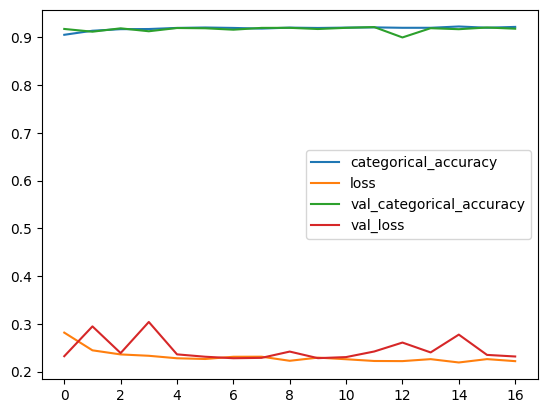

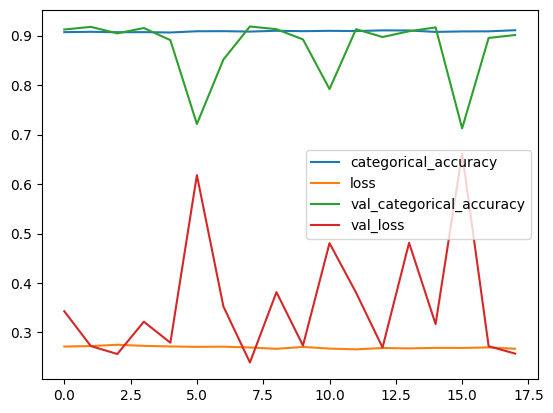

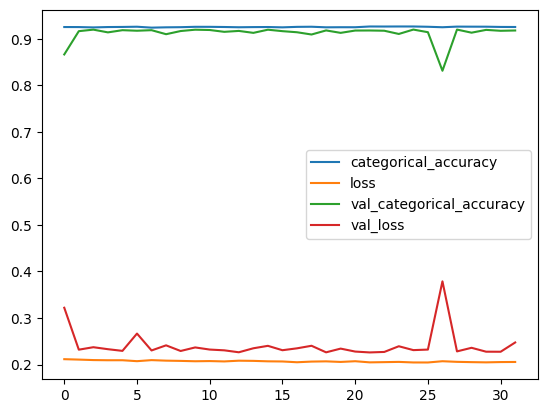

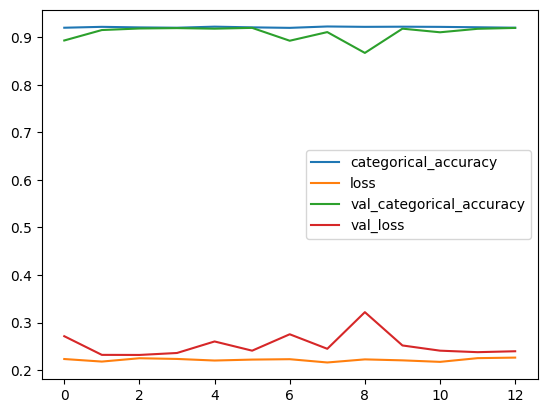

In [186]:
pd.DataFrame(history2.history).plot()
pd.DataFrame(history3.history).plot()
pd.DataFrame(history4.history).plot()
pd.DataFrame(history5.history).plot()

# **به دلیل کمبود منابع سخت افزاری بعضی مقایسه ها ناقص هستند ممنون از درک شما منتور محترم**



